# Logistic regression in PyTorch

The same model as in the NumPy lab, built with `nn.Linear` + sigmoid and trained with `torch.optim`,
on the breast cancer dataset (0 = malignant, 1 = benign).
Experiments: verification against the from-scratch NumPy implementation, optimizers, learning rate, metrics.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from data import load_breast_cancer_split, majority_baseline, to_tensors
from model import (
    LogisticRegressionTorch,
    accuracy,
    load_numpy_reference,
    set_seed,
    train,
)

In [2]:
DRIVE_ASSETS = Path("/content/drive/MyDrive/data/01-foundations/logistic-regression/assets")
LOCAL_ASSETS = Path("../assets")   # for local machine

ASSETS = DRIVE_ASSETS if Path("/content/drive/MyDrive").exists() else LOCAL_ASSETS
ASSETS.mkdir(parents=True, exist_ok=True)
print("Saving assets to:", ASSETS.resolve())

SEED = 0

Saving assets to: /Users/iharharkusha/Documents/nyawmolny/deep-learning-fundamentals/01-foundations/logistic-regression/assets


## 1. Data

In [3]:
X_train_np, X_test_np, y_train_np, y_test_np = load_breast_cancer_split()
X_train, y_train = to_tensors(X_train_np, y_train_np)
X_test, y_test = to_tensors(X_test_np, y_test_np)

print("X_train:", tuple(X_train.shape), "| X_test:", tuple(X_test.shape))
print("benign share (train):", y_train_np.mean().round(3))
print(f"majority-class baseline, test accuracy: {majority_baseline(y_train_np, y_test_np):.1%}")

X_train: (455, 30) | X_test: (114, 30)
benign share (train): 0.637
majority-class baseline, test accuracy: 58.8%


## 2. Baseline: SGD, lr=0.01, 1000 epochs

train acc: 97.6% | test acc: 95.6%


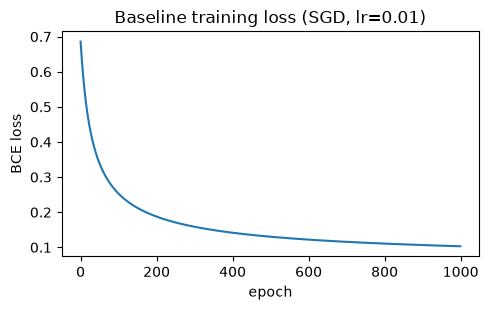

In [4]:
def run(make_optimizer, num_epochs, zero_init=False):
    set_seed(SEED)
    model = LogisticRegressionTorch(X_train.shape[1])
    if zero_init:
        model.zero_init()
    losses = train(model, X_train, y_train, make_optimizer(model.parameters()), num_epochs)
    return model, losses


model, losses = run(lambda p: torch.optim.SGD(p, lr=0.01), 1000)
print(f"train acc: {accuracy(model, X_train, y_train):.1%} | test acc: {accuracy(model, X_test, y_test):.1%}")

plt.figure(figsize=(5, 3.2))
plt.plot(losses)
plt.xlabel("epoch")
plt.ylabel("BCE loss")
plt.title("Baseline training loss (SGD, lr=0.01)")
plt.tight_layout()
plt.savefig(ASSETS / "torch_loss_curve.png", dpi=150)
plt.show()

## 3. Verification against the NumPy implementation

Same data, zero initialization, same learning rate, full batch, float64.
If both implementations are correct, loss curves and final weights must coincide.

max |loss difference|  : 1.7208456881689926e-15
max |weight difference|: 1.787459069646502e-14


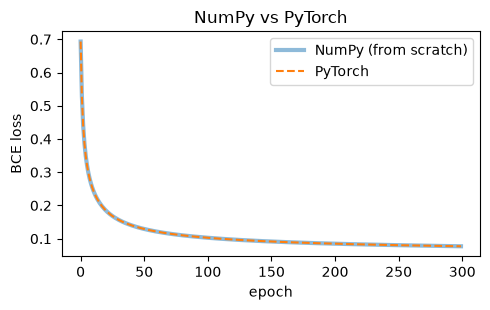

In [5]:
ref = load_numpy_reference()
LR, EPOCHS = 0.1, 300

np_model = ref.LogisticRegression(learning_rate=LR, num_iterations=EPOCHS, log_every=1).fit(
    X_train_np.T, y_train_np.reshape(1, -1)
)

t_model = LogisticRegressionTorch(X_train_np.shape[1]).double()
t_model.zero_init()
X64, y64 = to_tensors(X_train_np, y_train_np, dtype=torch.float64)
t_losses = train(t_model, X64, y64, torch.optim.SGD(t_model.parameters(), lr=LR), EPOCHS)

print("max |loss difference|  :", np.max(np.abs(np.array(t_losses) - np.array(np_model.costs_))))
print("max |weight difference|:", np.max(np.abs(t_model.linear.weight.detach().numpy().T - np_model.w)))

plt.figure(figsize=(5, 3.2))
plt.plot(np_model.costs_, label="NumPy (from scratch)", linewidth=3, alpha=0.5)
plt.plot(t_losses, "--", label="PyTorch")
plt.xlabel("epoch")
plt.ylabel("BCE loss"); plt.legend()
plt.title("NumPy vs PyTorch")
plt.tight_layout()
plt.savefig(ASSETS / "torch_vs_numpy.png", dpi=150)
plt.show()

## 4. Learning rate (SGD, 300 epochs)

lr=0.001  final loss=0.4117  train=90.1%  test=91.2%
lr=0.01   final loss=0.1587  train=96.9%  test=95.6%
lr=0.1    final loss=0.0772  train=98.5%  test=96.5%
lr=1.0    final loss=0.0526  train=98.9%  test=96.5%


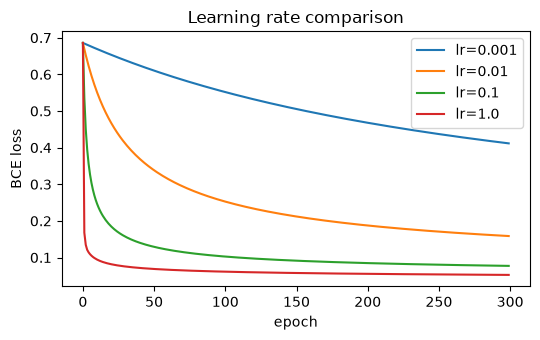

In [7]:
plt.figure(figsize=(5.5, 3.5))
for lr in [0.001, 0.01, 0.1, 1.0]:
    m, l = run(lambda p, lr=lr: torch.optim.SGD(p, lr=lr), 300)
    plt.plot(l, label=f"lr={lr}")
    print(f"lr={lr:<6} final loss={l[-1]:.4f}  train={accuracy(m, X_train, y_train):.1%}  test={accuracy(m, X_test, y_test):.1%}")

plt.xlabel("epoch")
plt.ylabel("BCE loss")
plt.legend()
plt.title("Learning rate comparison")
plt.tight_layout()
plt.savefig(ASSETS / "torch_lr_comparison.png", dpi=150)
plt.show()

## 5. Results and notes

### NumPy vs PyTorch
Max |loss diff| = 1.7e-15, max |weight diff| = 1.8e-14 — essentially zero. 
The two implementations are numerically identical.
Any real bug would show more significant difference, not 1e-15.

### Learning rate (SGD, 300 epochs, 0.5 threshold)

| lr    | final loss | train  | test   | train − test gap |
|-------|-----------:|-------:|-------:|-----------------:|
| 0.001 | 0.4117     | 90.1%  | 91.2%  | −1.1 pp          |
| 0.01  | 0.1587     | 96.9%  | 95.6%  | +1.3 pp          |
| 0.1   | 0.0772     | 98.5%  | 96.5%  | +2.0 pp          |
| 1.0   | 0.0526     | 98.9%  | 96.5%  | +2.4 pp          |

- **`lr = 0.001` — too small.** Still far from the minimum after 300 epochs; underfits both splits.

- **`lr = 0.01` — sweet spot.** Smallest train–test gap among the converged runs, best test accuracy.

- **`lr = 0.1` — a bit aggressive.** Gap grows to ~2 pp; train keeps improving, test plateaus at 96.5%.

- **`lr = 1.0` — overfitting trend continues** (gap ~2.4 pp). No divergence on this convex full-batch run, but larger steps widen the gap without improving test accuracy.

### Test accuracy vs the majority baseline
Majority baseline: **58.8%**. 
Trained model: **95.6–96.5%** for `lr ≥ 0.01` — **+37 pp**. 
So it learns real signal, not just the class prior.